# Team color assignment (robust version)

Instead of running k-means on every crop to separate shirt from background:

1. For each player, take a **narrow torso box** (mostly shirt, very little background).
2. The player's color = **median Lab color** of that box (the median ignores the number, trim, a bit of court...).
3. **Skip crops whose box overlaps someone else**, since they mix two shirts.
4. Run **k-means with k = 2 over every player in every frame** → two teams.
5. Each **track ID gets the majority vote** over all its frames.

In [1]:
import cv2
import pickle
import collections
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
video_path = "../data/EON.mp4"
stub_path = "../stubs/EON.pkl"

# ! Read every frame of the video
cap = cv2.VideoCapture(video_path)
frames = []
while True:
  found, frame = cap.read()
  if not found:
    break
  frames.append(frame)
cap.release()

# ! Tracks generated by main.py
with open(stub_path, "rb") as f:
  tracks = pickle.load(f)

print("frames:", len(frames), "| tracked frames:", len(tracks["players"]))

frames: 622 | tracked frames: 622


In [3]:
def all_bboxes(frame_num):
  # ! players + goalkeepers + referees in a frame
  return [obj["bbox"] for key in ("players", "gks", "referees") for obj in tracks[key][frame_num].values()]

def get_torso(frame, bbox, width_margin=0.25):
  # ! 15-50 % of the height (no head, no shorts), middle half of the width (little background)
  x1, y1, x2, y2 = map(int, bbox)
  h, w = y2 - y1, x2 - x1
  return frame[y1 + int(0.15 * h) : y1 + int(0.5 * h), x1 + int(width_margin * w) : x2 - int(width_margin * w)]

def to_lab(pixels_bgr):
  return cv2.cvtColor(pixels_bgr.reshape(-1, 1, 3), cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(float)

# 1. Why not just remove the court pixels?

The obvious idea is to delete every court-colored pixel and keep the rest.
In this video that **doesn't work**: under the arena lights the "white" shirts are actually a light blue,
very close to the court. Let's measure it in Lab (distance = how different two colors are).

In [4]:
frame_num = 5
frame = frames[frame_num]
lab_frame = to_lab(frame).reshape(frame.shape)

# ! Court color: lower 2/3 of the frame with every person hidden
mask = np.ones(frame.shape[:2], dtype=bool)
mask[: frame.shape[0] // 3] = False
for x1, y1, x2, y2 in all_bboxes(frame_num):
  mask[int(y1):int(y2), int(x1):int(x2)] = False
court_lab = np.median(lab_frame[mask], axis=0)
court_spread = np.median(np.linalg.norm(lab_frame[mask] - court_lab, axis=1))

print("court Lab:", court_lab.astype(int), "| typical court-to-court distance:", round(court_spread, 1))
for track_id, player in list(tracks["players"][frame_num].items())[:6]:
  shirt_lab = np.median(to_lab(get_torso(frame, player["bbox"])), axis=0)
  print(f"id {track_id}: shirt Lab {shirt_lab.astype(int)} | distance to court {np.linalg.norm(shirt_lab - court_lab):.1f}")

court Lab: [163 124  96] | typical court-to-court distance: 35.7
id 0: shirt Lab [144 128 106] | distance to court 21.8
id 2: shirt Lab [ 46 130 117] | distance to court 119.0
id 3: shirt Lab [ 93 129 112] | distance to court 71.5
id 4: shirt Lab [146 128 103] | distance to court 18.8
id 5: shirt Lab [118 127 105] | distance to court 46.0
id 6: shirt Lab [153 128 107] | distance to court 15.4


The white shirts are about as far from the court as the court is from itself (lighting, reflections, ads),
so any "remove court-colored pixels" threshold also removes the shirt.
The narrow torso box + median is simpler and works better: the box is mostly shirt, and the median ignores the rest.

# 2. Player color — check it on a few players

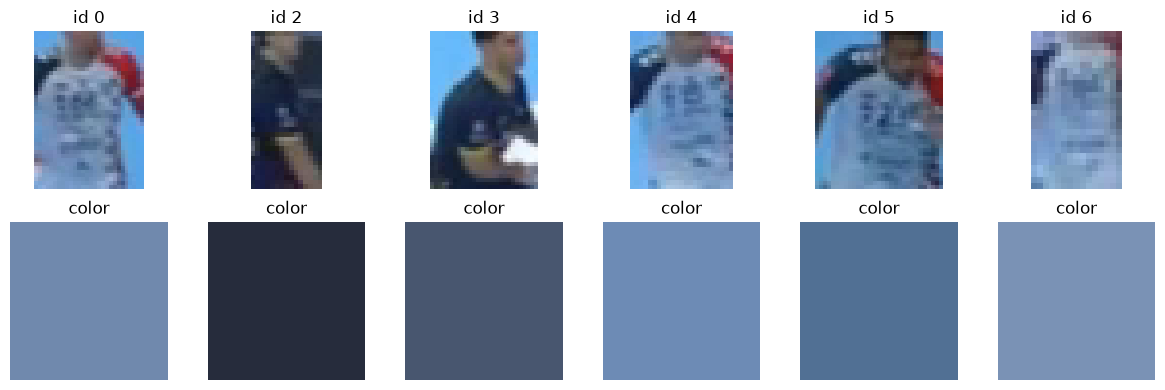

In [5]:
def get_player_color(frame, bbox):
  torso = get_torso(frame, bbox)
  if torso.size < 30:   # ! too small to trust
    return None
  return np.median(to_lab(torso), axis=0)

players = list(tracks["players"][frame_num].items())[:6]
fig, ax = plt.subplots(2, len(players), figsize=(2 * len(players), 4))
for col, (track_id, player) in enumerate(players):
  torso = get_torso(frame, player["bbox"])
  lab = get_player_color(frame, player["bbox"])
  rgb = cv2.cvtColor(np.full((10, 10, 3), lab.astype(np.uint8)), cv2.COLOR_LAB2RGB)
  ax[0, col].imshow(cv2.cvtColor(torso, cv2.COLOR_BGR2RGB)); ax[0, col].set_title(f"id {track_id}")
  ax[1, col].imshow(rgb);                                    ax[1, col].set_title("color")
for a in ax.ravel():
  a.axis("off")
plt.tight_layout(); plt.show()

# 3. Collect a color for every player in every frame

Crops whose box overlaps another person are skipped: their torso box contains two shirts.

In [7]:
def boxes_overlap(a, b):
  return not (a[2] < b[0] or b[2] < a[0] or a[3] < b[1] or b[3] < a[1])

records = []   # ! (frame_num, track_id, lab_color)
skipped = 0
for frame_num, players in enumerate(tracks["players"]):
  others = all_bboxes(frame_num)
  for track_id, player in players.items():
    bbox = player["bbox"]
    if any(boxes_overlap(bbox, o) for o in others if o is not bbox):
      skipped += 1
      continue
    color = get_player_color(frames[frame_num], bbox)
    if color is not None:
      records.append((frame_num, track_id, color))

print("colors collected:", len(records), "| skipped (overlapping):", skipped)

colors collected: 3857 | skipped (overlapping): 2132


# 4. Two teams with k-means (k = 2) + majority vote per track ID

In [8]:
colors = np.array([r[2] for r in records])
team_kmeans = KMeans(n_clusters=2, n_init=10, random_state=0).fit(colors)

votes = collections.defaultdict(collections.Counter)
for (frame_num, track_id, _), label in zip(records, team_kmeans.labels_):
  votes[track_id][label] += 1

player_team = {track_id: c.most_common(1)[0][0] for track_id, c in votes.items()}

print("team centers (Lab):\n", team_kmeans.cluster_centers_.astype(int))
for track_id in sorted(votes):
  c = votes[track_id]
  total = sum(c.values())
  agreement = c[player_team[track_id]] / total
  flag = "  <-- unsure (occlusion or tracker ID switch?)" if agreement < 0.9 else ""
  print(f"id {track_id:3d} -> team {player_team[track_id]} | {agreement:.0%} of {total} frames{flag}")

team centers (Lab):
 [[139 128 107]
 [ 63 128 114]]
id   0 -> team 0 | 100% of 87 frames
id   2 -> team 1 | 100% of 99 frames
id   3 -> team 1 | 95% of 99 frames
id   4 -> team 0 | 100% of 79 frames
id   5 -> team 0 | 53% of 106 frames  <-- unsure (occlusion or tracker ID switch?)
id   6 -> team 0 | 100% of 99 frames
id   7 -> team 0 | 100% of 2 frames
id   8 -> team 0 | 100% of 98 frames
id   9 -> team 1 | 100% of 77 frames
id  10 -> team 1 | 100% of 3 frames
id  11 -> team 1 | 97% of 31 frames
id  12 -> team 1 | 94% of 35 frames
id  14 -> team 1 | 100% of 5 frames
id  15 -> team 0 | 69% of 32 frames  <-- unsure (occlusion or tracker ID switch?)
id  16 -> team 1 | 100% of 28 frames
id  17 -> team 1 | 100% of 7 frames
id  18 -> team 1 | 100% of 37 frames
id  19 -> team 0 | 86% of 14 frames  <-- unsure (occlusion or tracker ID switch?)
id  20 -> team 1 | 66% of 412 frames  <-- unsure (occlusion or tracker ID switch?)
id  21 -> team 0 | 95% of 21 frames
id  22 -> team 1 | 65% of 266 fram

# 5. Draw the result on a frame

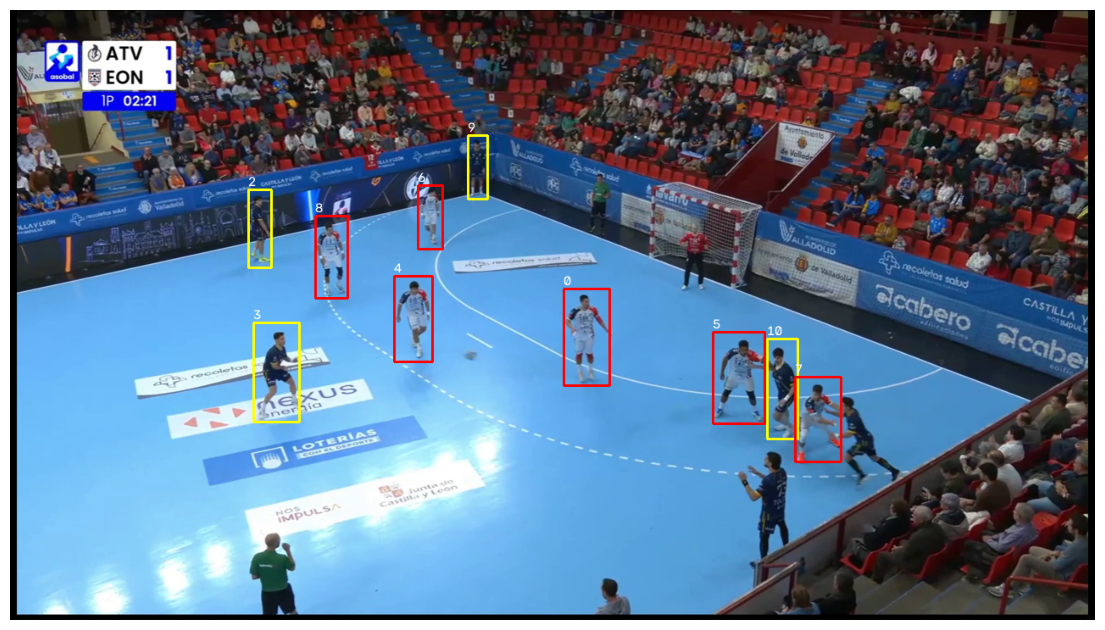

In [9]:
# ! Fixed, easy-to-see colors (BGR) for drawing; gray = no vote yet
TEAM_DRAW = {0: (0, 0, 255), 1: (0, 255, 255)}

frame_num = 5
out = frames[frame_num].copy()
for track_id, player in tracks["players"][frame_num].items():
  x1, y1, x2, y2 = map(int, player["bbox"])
  color = TEAM_DRAW.get(player_team.get(track_id), (128, 128, 128))
  cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
  cv2.putText(out, f"{track_id}", (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

# Notes

- The remaining "unsure" IDs are mostly **tracking problems**, not color problems: when the tracker gives the same ID
  to two different people (ID switch) or to a false detection (e.g. someone in the stands), no color method can fix it.
- Goalkeepers and referees are separate classes in the detector, so they never enter the team k-means.
- Team 0 / team 1 is arbitrary (k-means order); decide which is which by the center's brightness (L channel).